In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel('/content/weather_data_analysis_dataset.xlsx')
weather_raw = df.copy()  # Preserve original data before cleaning
df.head()

,Date,City,Temperature_C,Min_Temperature_C,Max_Temperature_C,Humidity_Percent,Rainfall_mm,Wind_Speed_kmh
0,2025-01-01,Delhi,20.9,15.5,24.6,57.4,0.0,3.2
1,2025-01-02,Delhi,20.5,18.0,25.6,39.5,0.0,13.1
2,2025-01-03,Delhi,20.3,16.5,25.6,39.4,13.4,11.3
3,2025-01-04,Delhi,19.7,13.8,23.1,46.5,0.0,8.5
4,2025-01-05,Delhi,21.3,18.7,23.4,52.3,0.0,17.5


In [54]:
# Check the number of rows and columns
df.shape

(1810, 8)

In [55]:
# Check column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1810 entries, 0 to 1809
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Date               1810 non-null   datetime64[ns]
 1   City               1810 non-null   object        
 2   Temperature_C      1765 non-null   float64       
 3   Min_Temperature_C  1810 non-null   float64       
 4   Max_Temperature_C  1810 non-null   float64       
 5   Humidity_Percent   1774 non-null   float64       
 6   Rainfall_mm        1783 non-null   float64       
 7   Wind_Speed_kmh     1810 non-null   float64       
dtypes: datetime64[ns](1), float64(6), object(1)
memory usage: 113.3+ KB


In [56]:
# Check missing values in each column
df.isnull().sum()

,0
Date,0
City,0
Temperature_C,45
Min_Temperature_C,0
Max_Temperature_C,0
Humidity_Percent,36
Rainfall_mm,27
Wind_Speed_kmh,0


In [57]:
df['Temperature_C'] = df['Temperature_C'].fillna(df['Temperature_C'].median())

df['Humidity_Percent'] = df['Humidity_Percent'].fillna(df['Humidity_Percent'].median())

df['Rainfall_mm'] = df['Rainfall_mm'].fillna(df['Rainfall_mm'].median())

In [58]:
df.isna().sum()

,0
Date,0
City,0
Temperature_C,0
Min_Temperature_C,0
Max_Temperature_C,0
Humidity_Percent,0
Rainfall_mm,0
Wind_Speed_kmh,0


In [59]:
# Check duplicate records
df.duplicated().sum()

np.int64(0)

In [60]:
# Check duplicate city-date combinations
df.duplicated(subset=['Date', 'City']).sum()

np.int64(0)

In [61]:
#Check the dataset's statistical summary
df.describe()

,Date,Temperature_C,Min_Temperature_C,Max_Temperature_C,Humidity_Percent,Rainfall_mm,Wind_Speed_kmh
count,1810,1810.000000,1810.000000,1810.000000,1810.000000,1810.000000,1810.000000
mean,2025-04-01 00:00:00,27.539061,23.540829,31.575359,59.350110,2.160387,10.859834
min,2025-01-01 00:00:00,15.400000,11.600000,18.500000,20.000000,0.000000,0.000000
25%,2025-02-15 00:00:00,23.900000,19.625000,27.700000,48.100000,0.000000,8.300000
50%,2025-04-01 00:00:00,27.100000,23.200000,31.200000,59.500000,0.000000,10.900000
75%,2025-05-16 00:00:00,31.100000,27.100000,35.200000,70.300000,0.700000,13.500000
max,2025-06-30 00:00:00,45.200000,43.100000,49.000000,100.000000,33.200000,24.000000
std,NaN,4.948064,5.144279,5.171115,14.936125,4.889607,3.840072


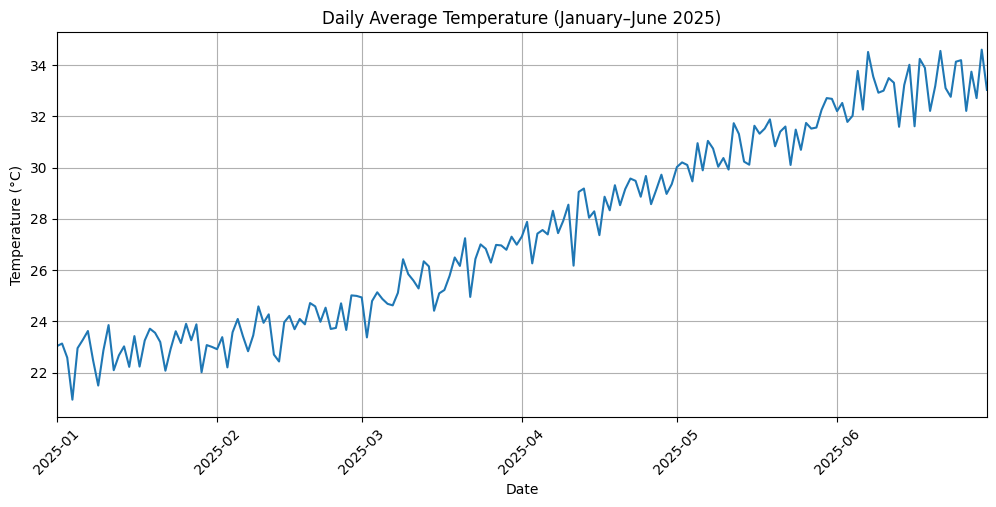

In [62]:
# Calculate daily average temperature
daily_temp = df.groupby('Date')['Temperature_C'].mean()

# Plot the temperature trend
plt.figure(figsize=(12, 5))
plt.plot(daily_temp.index, daily_temp.values)
plt.title('Daily Average Temperature (January–June 2025)')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.xlim(df['Date'].min(),df['Date'].max())
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

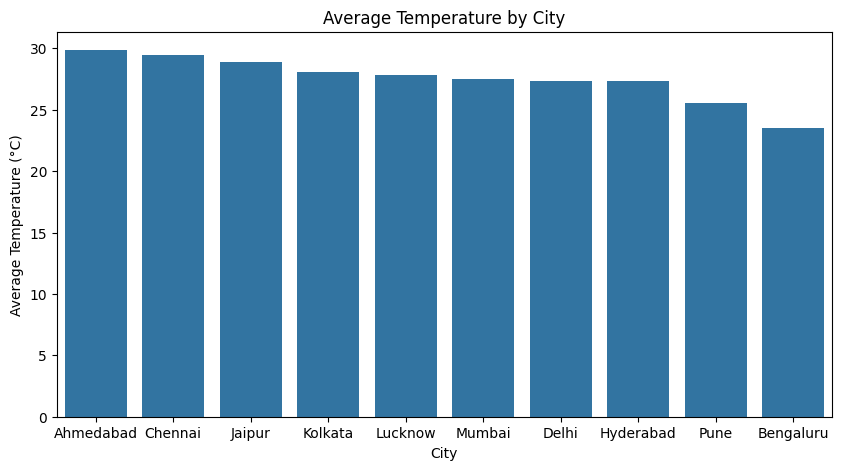

In [63]:
# Calculate average temperature by city
city_temp = df.groupby('City')['Temperature_C'].mean().sort_values(ascending=False)
# Create a bar chart
plt.figure(figsize=(10, 5))
sns.barplot(x=city_temp.index, y=city_temp.values)
plt.title('Average Temperature by City')
plt.xlabel('City')
plt.ylabel('Average Temperature (°C)')
plt.show()

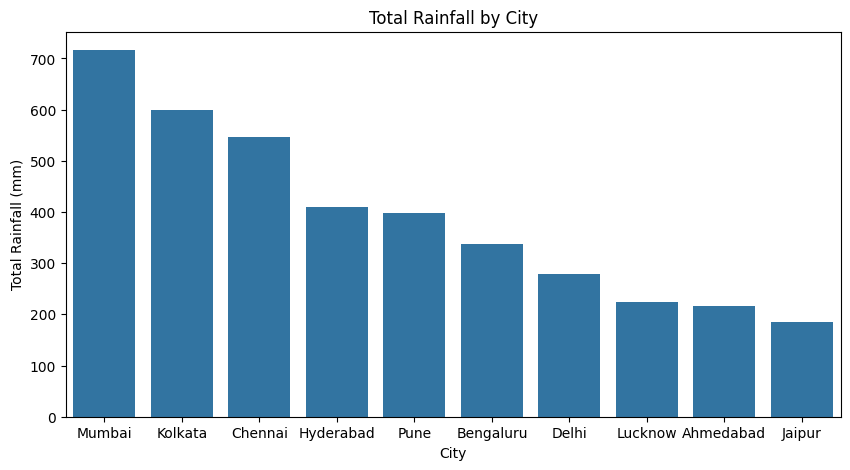

In [64]:
# Calculate total rainfall by city
city_rainfall = df.groupby('City')['Rainfall_mm'].sum().sort_values(ascending=False)
# Create a bar chart
plt.figure(figsize=(10, 5))
sns.barplot(x=city_rainfall.index, y=city_rainfall.values)
plt.title('Total Rainfall by City')
plt.xlabel('City')
plt.ylabel('Total Rainfall (mm)')
plt.show()

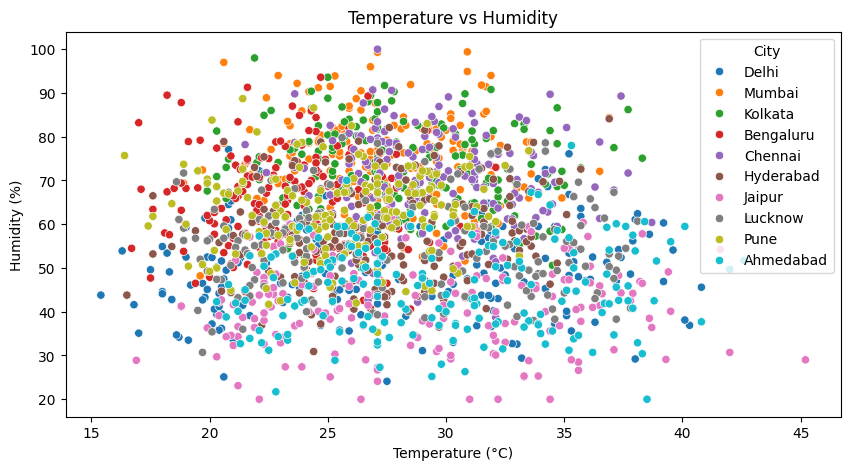

In [65]:
# Visualize the relationship between temperature and humidity
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x='Temperature_C', y='Humidity_Percent', hue='City')
plt.title('Temperature vs Humidity')
plt.xlabel('Temperature (°C)')
plt.ylabel('Humidity (%)')
plt.show()

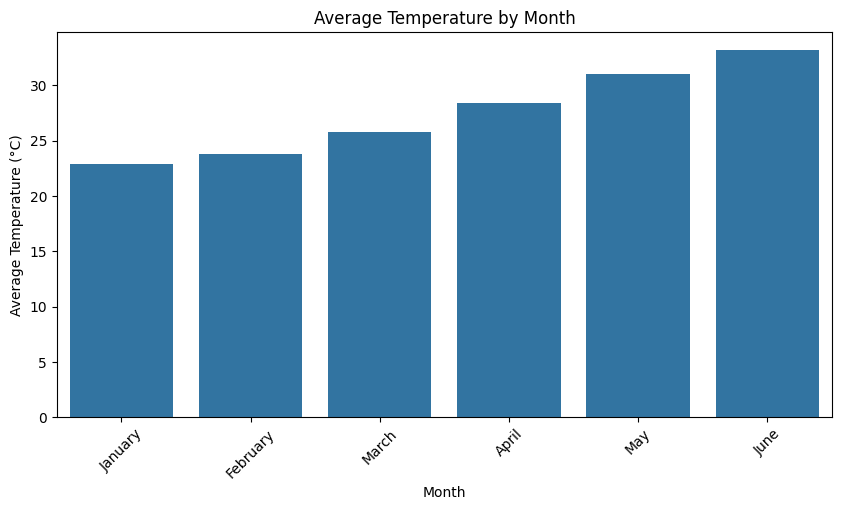

In [66]:
# Calculate average temperature for each month
df['Month'] = df['Date'].dt.month_name()
monthly_temp = df.groupby('Month')['Temperature_C'].mean().reindex(
    ['January', 'February', 'March', 'April', 'May', 'June']
)
# Visualize monthly average temperature
plt.figure(figsize=(10, 5))
sns.barplot(x=monthly_temp.index, y=monthly_temp.values)
plt.title('Average Temperature by Month')
plt.xlabel('Month')
plt.ylabel('Average Temperature (°C)')
plt.xticks(rotation=45)
plt.show()

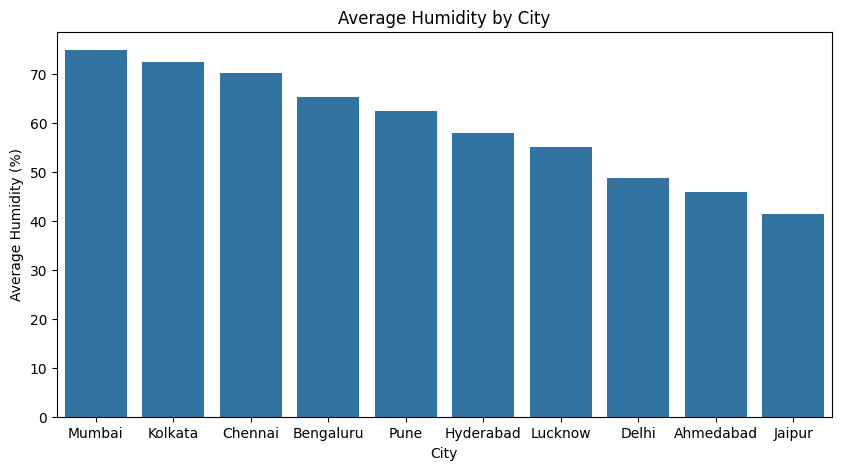

In [67]:
# Calculate average humidity for each city
city_humidity = df.groupby('City')['Humidity_Percent'].mean().sort_values(ascending=False)
# Visualize average humidity by city
plt.figure(figsize=(10, 5))
sns.barplot(x=city_humidity.index, y=city_humidity.values)
plt.title('Average Humidity by City')
plt.xlabel('City')
plt.ylabel('Average Humidity (%)')
plt.show()

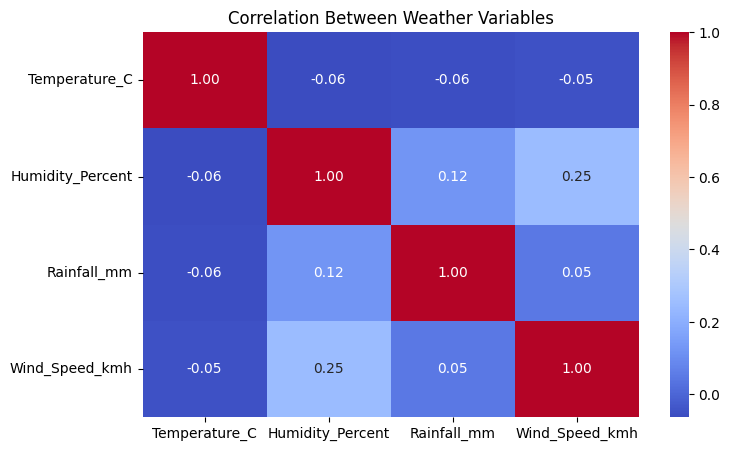

In [68]:
# Select numerical weather columns
correlation = df[['Temperature_C', 'Humidity_Percent', 'Rainfall_mm', 'Wind_Speed_kmh']].corr()

# Visualize the correlation matrix
plt.figure(figsize=(8, 5))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Between Weather Variables')
plt.show()

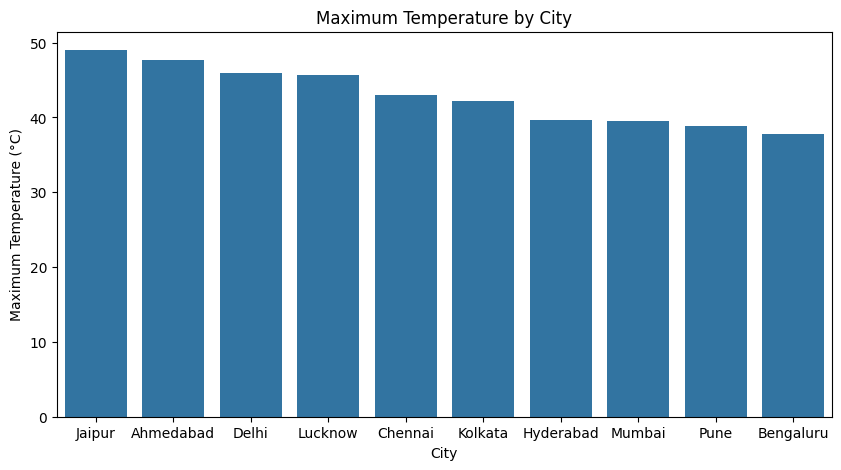

In [69]:
# Calculate the highest recorded temperature for each city
city_max_temp = df.groupby('City')['Max_Temperature_C'].max().sort_values(ascending=False)
# Visualize maximum temperature by city
plt.figure(figsize=(10, 5))
sns.barplot(x=city_max_temp.index, y=city_max_temp.values)
plt.title('Maximum Temperature by City')
plt.xlabel('City')
plt.ylabel('Maximum Temperature (°C)')
plt.show()

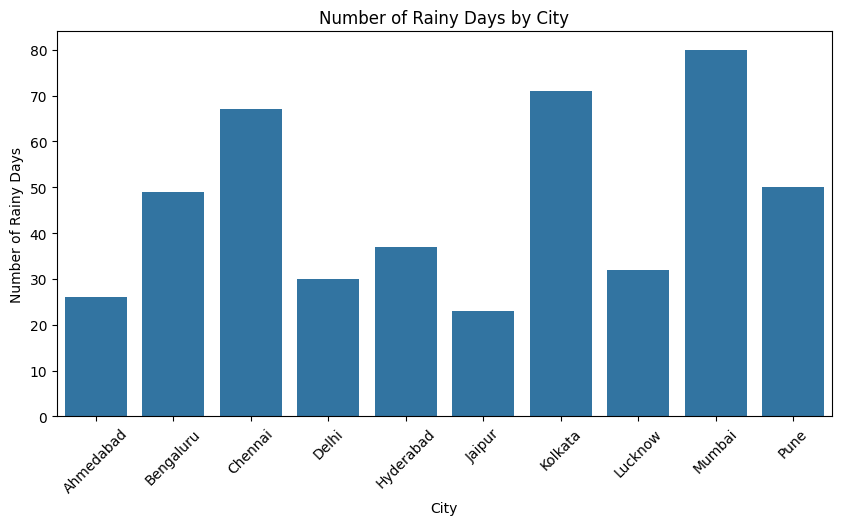

In [70]:
# Count rainy days for each city
rainy_days = df[df['Rainfall_mm'] > 0].groupby('City')['Date'].count()
# Visualize rainy days by city
plt.figure(figsize=(10, 5))
sns.barplot(x=rainy_days.index, y=rainy_days.values)
plt.title('Number of Rainy Days by City')
plt.xlabel('City')
plt.ylabel('Number of Rainy Days')
plt.xticks(rotation=45)
plt.show()

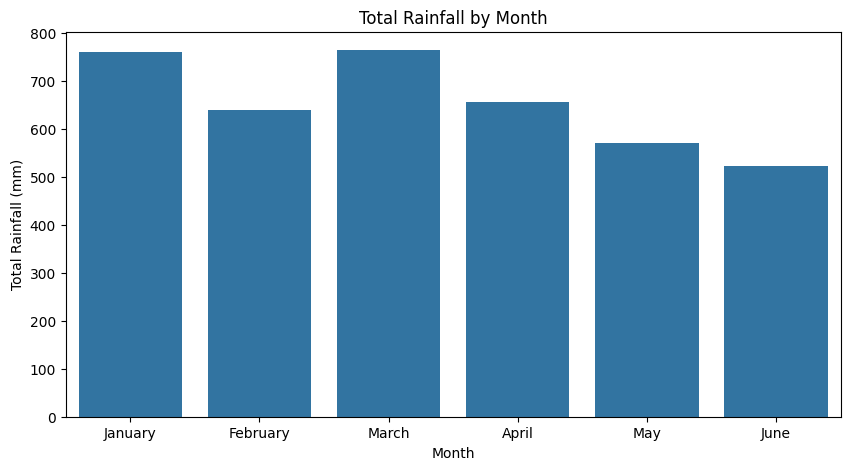

In [71]:
# Calculate total rainfall for each month
monthly_rainfall = df.groupby('Month')['Rainfall_mm'].sum().reindex(
    ['January', 'February', 'March', 'April', 'May', 'June']
)
# Visualize monthly rainfall
plt.figure(figsize=(10, 5))
sns.barplot(x=monthly_rainfall.index, y=monthly_rainfall.values)
plt.title('Total Rainfall by Month')
plt.xlabel('Month')
plt.ylabel('Total Rainfall (mm)')
plt.show()

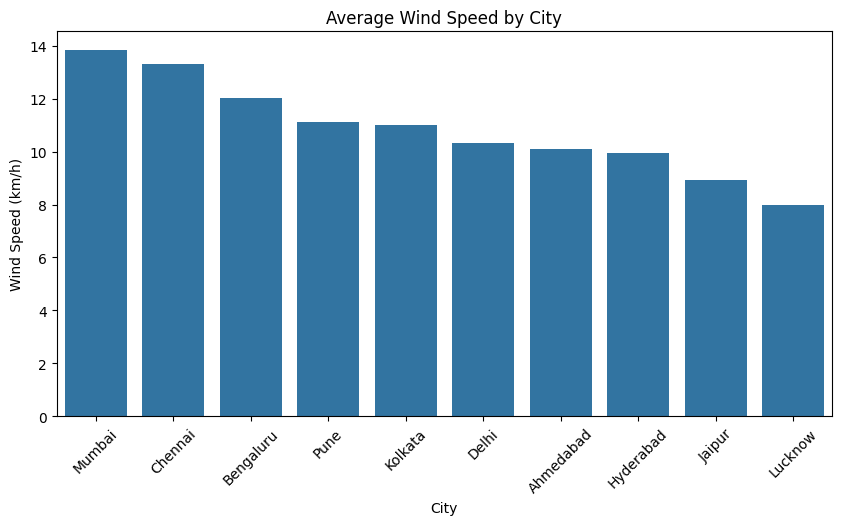

In [72]:
# Calculate average wind speed for each city
city_wind = df.groupby('City')['Wind_Speed_kmh'].mean().sort_values(ascending=False)
# Visualize average wind speed
plt.figure(figsize=(10, 5))
sns.barplot(x=city_wind.index, y=city_wind.values)
plt.title('Average Wind Speed by City')
plt.xlabel('City')
plt.ylabel('Wind Speed (km/h)')
plt.xticks(rotation=45)
plt.show()

In [73]:
# Calculate the first and third quartiles
Q1 = df['Temperature_C'].quantile(0.25)
Q3 = df['Temperature_C'].quantile(0.75)
# Calculate the interquartile range
IQR = Q3 - Q1
# Calculate the upper limit
upper_limit = Q3 + (1.5 * IQR)
# Find unusually high temperatures
high_temp = df[df['Temperature_C'] > upper_limit]
# Display the results
high_temp[['Date', 'City', 'Temperature_C']]

,Date,City,Temperature_C
1243,2025-06-07,Jaipur,45.2
1255,2025-06-19,Jaipur,42.0
1428,2025-06-11,Lucknow,42.8
1778,2025-05-30,Ahmedabad,42.0
1793,2025-06-14,Ahmedabad,42.6


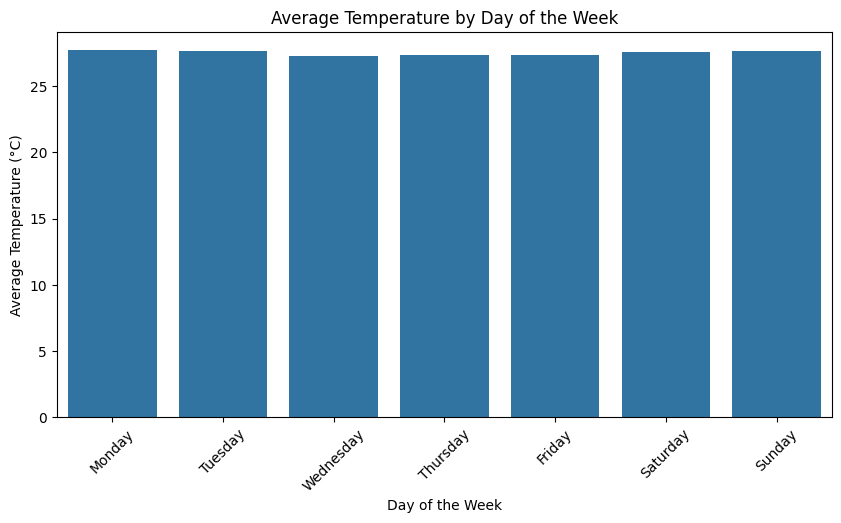

In [74]:
# Extract the day name from the date
df['Day'] = df['Date'].dt.day_name()

# Calculate average temperature by day
day_temp = df.groupby('Day')['Temperature_C'].mean().reindex(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
)
# Visualize average temperature by day
plt.figure(figsize=(10, 5))
sns.barplot(x=day_temp.index, y=day_temp.values)
plt.title('Average Temperature by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Temperature (°C)')
plt.xticks(rotation=45)
plt.show()

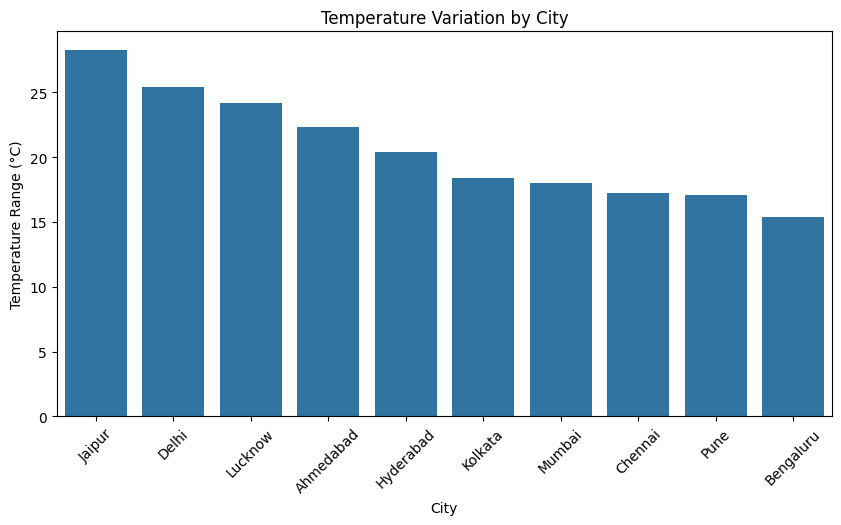

In [75]:
# Calculate temperature variation for each city
city_temp_range = df.groupby('City')['Temperature_C'].max() - df.groupby('City')['Temperature_C'].min()

# Sort cities by temperature variation
city_temp_range = city_temp_range.sort_values(ascending=False)

# Visualize temperature variation
plt.figure(figsize=(10, 5))
sns.barplot(x=city_temp_range.index, y=city_temp_range.values)
plt.title('Temperature Variation by City')
plt.xlabel('City')
plt.ylabel('Temperature Range (°C)')
plt.xticks(rotation=45)
plt.show()

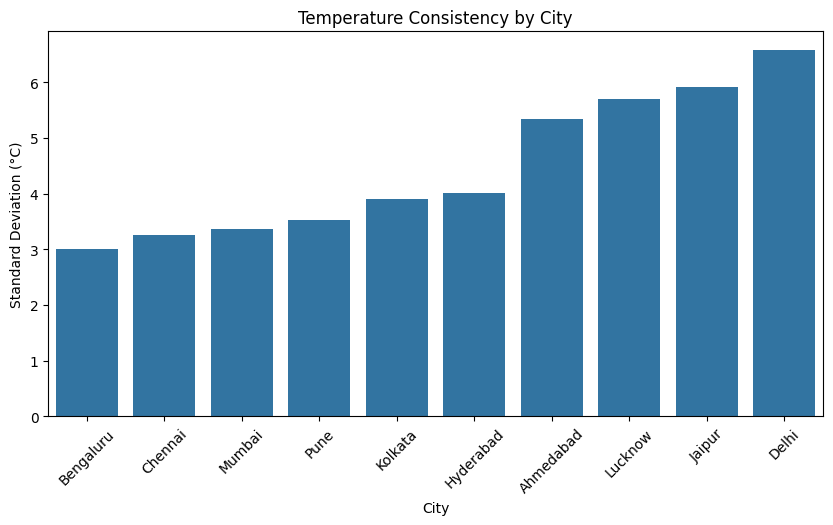

In [76]:
# Calculate temperature standard deviation for each city
city_temp_std = df.groupby('City')['Temperature_C'].std().sort_values()

# Visualize temperature consistency
plt.figure(figsize=(10, 5))
sns.barplot(x=city_temp_std.index, y=city_temp_std.values)

plt.title('Temperature Consistency by City')
plt.xlabel('City')
plt.ylabel('Standard Deviation (°C)')
plt.xticks(rotation=45)

plt.show()

In [77]:
# Sort data by city and date
df = df.sort_values(['City', 'Date'])

# Get the previous day's temperature for each city
df['Previous_Day_Temp'] = df.groupby('City')['Temperature_C'].shift(1)

# Compare previous day's temperature with the current day's temperature
df[['Date', 'City', 'Temperature_C','Previous_Day_Temp']].head(10)

,Date,City,Temperature_C,Previous_Day_Temp
1629,2025-01-01,Ahmedabad,21.3,NaN
1630,2025-01-02,Ahmedabad,25.9,21.3
1631,2025-01-03,Ahmedabad,20.7,25.9
1632,2025-01-04,Ahmedabad,22.9,20.7
1633,2025-01-05,Ahmedabad,22.5,22.9
1634,2025-01-06,Ahmedabad,25.2,22.5
1635,2025-01-07,Ahmedabad,27.4,25.2
1636,2025-01-08,Ahmedabad,24.2,27.4
1637,2025-01-09,Ahmedabad,22.3,24.2
1638,2025-01-10,Ahmedabad,21.5,22.3


In [78]:
# Sort original data by city and date
prediction_data = weather_raw[['Date', 'City', 'Temperature_C']].copy()
prediction_data = prediction_data.sort_values(['City', 'Date'])

# Use the previous day's temperature as the prediction
prediction_data['Predicted_Temp'] = (
    prediction_data.groupby('City')['Temperature_C'].shift(1)
)

# Calculate absolute prediction error
prediction_data['Prediction_Error'] = abs(
    prediction_data['Temperature_C'] - prediction_data['Predicted_Temp']
)

# Calculate Mean Absolute Error
mean_error = prediction_data['Prediction_Error'].mean()

print("Mean Absolute Error (MAE):", round(mean_error, 2), "°C")

Mean Absolute Error (MAE): 2.5 °C
